# 12. Vision-Language-Action Models

## 1. From Vision-Language Models to Robot Actions

Vision-Language Models (VLMs) combine visual observations
and language instructions to generate textual responses.

Vision-Language-Action Models (VLAs) extend this paradigm
to robot control.

A VLA policy can be expressed as:

$$
A_t = \pi_\theta(I_t, L, s_t)
$$

where:

- $I_t$ is the visual observation.
- $L$ is the language instruction.
- $s_t$ is the robot state, when available.
- $A_t$ is a predicted action or action chunk.

Two important approaches are:

**OpenVLA:** discretizes continuous robot actions into
action tokens and predicts them autoregressively.

**π₀ (pi-zero):** uses a vision-language backbone and
a flow-matching action expert to generate continuous
action chunks.

These architectures connect concepts explored earlier
in the course: visual encoders, language conditioning,
Transformers, action chunking, and flow matching.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

NUM_BINS = 256

def quantize_action(action, num_bins=NUM_BINS):
    action = np.asarray(action, dtype=np.float32)
    action = np.clip(action, -1.0, 1.0)

    return np.rint(
        (action + 1.0) / 2.0 * (num_bins - 1)
    ).astype(np.int64)


def dequantize_action(tokens, num_bins=NUM_BINS):
    tokens = np.asarray(tokens)

    return (
        2.0 * tokens / (num_bins - 1) - 1.0
    )


action = np.array([0.35, -0.72])

tokens = quantize_action(action)
reconstructed = dequantize_action(tokens)

print("Original action:     ", action)
print("Discrete tokens:     ", tokens)
print("Reconstructed action:", reconstructed)
print("Quantization error:  ", reconstructed - action)

Original action:      [ 0.35 -0.72]
Discrete tokens:      [172  36]
Reconstructed action: [ 0.34901961 -0.71764706]
Quantization error:   [-0.00098039  0.00235294]


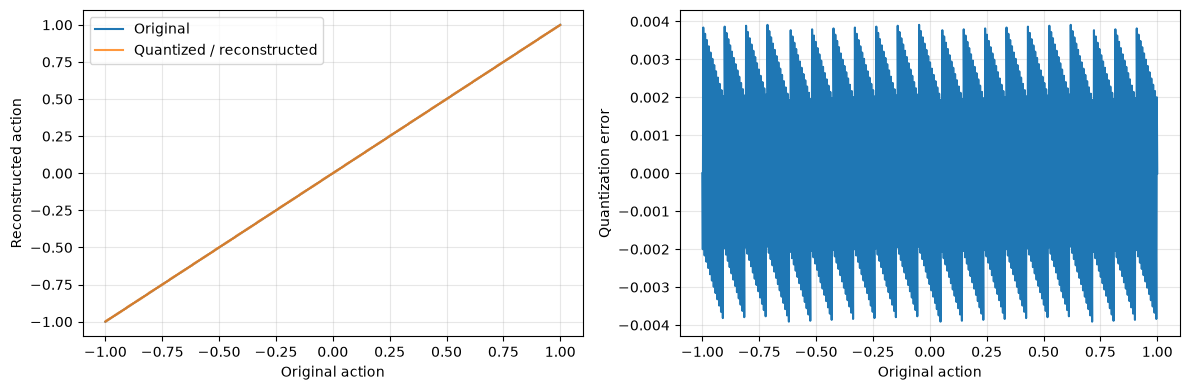

Maximum absolute error: 0.003909792145086355


In [2]:
values = np.linspace(-1.0, 1.0, 1000)

quantized = quantize_action(values)
reconstructed = dequantize_action(quantized)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(values, values, label="Original")
axes[0].plot(
    values,
    reconstructed,
    label="Quantized / reconstructed",
    alpha=0.8,
)
axes[0].set_xlabel("Original action")
axes[0].set_ylabel("Reconstructed action")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(values, reconstructed - values)
axes[1].set_xlabel("Original action")
axes[1].set_ylabel("Quantization error")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(
    "Maximum absolute error:",
    np.max(np.abs(reconstructed - values))
)

## 2. Action Tokenization on PushT

OpenVLA-style action generation represents continuous robot
actions using discrete tokens.

Before quantization, continuous actions must be normalized
to a known numerical range.

For a robot action vector:

$$
a_t \in \mathbb{R}^{D_a}
$$

we can normalize each action dimension independently:

$$
\tilde{a}_{t,d}
=
2\frac{a_{t,d}-a_{\min,d}}
{a_{\max,d}-a_{\min,d}}-1
$$

The normalized values lie in $[-1,1]$ and can be mapped
to discrete bins.

In this experiment, we use the PushT dataset, where
actions represent 2D target positions.

We first inspect the action distribution to determine
appropriate normalization bounds.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from lerobot.datasets.lerobot_dataset import LeRobotDataset

dataset = LeRobotDataset("lerobot/pusht")

print("Dataset size:", len(dataset))

# Extract all 2D actions
actions = np.stack([
    dataset[i]["action"].numpy()
    for i in range(len(dataset))
])

print("Actions shape:", actions.shape)

action_min = actions.min(axis=0)
action_max = actions.max(axis=0)

print("Action min:", action_min)
print("Action max:", action_max)
print("Action mean:", actions.mean(axis=0))
print("Action std:", actions.std(axis=0))

/Users/terreran/Documents/ws-playground/robot-learning-playground/.pixi/envs/default/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1145.52it/s]


Dataset size: 25650
Actions shape: (25650, 2)
Action min: [12. 25.]
Action max: [511. 511.]
Action mean: [228.23965 293.98907]
Action std: [101.59955  96.03693]


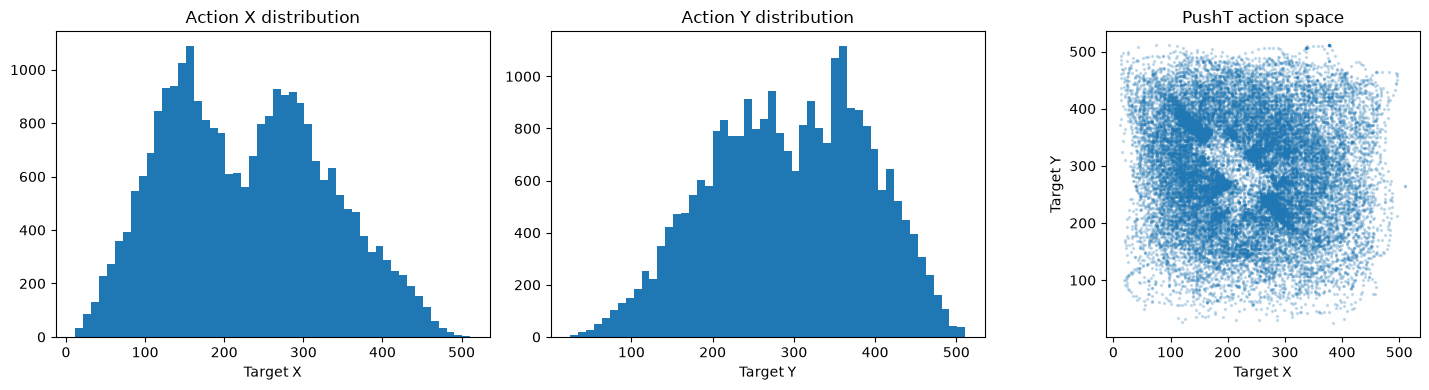

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(actions[:, 0], bins=50)
axes[0].set_title("Action X distribution")
axes[0].set_xlabel("Target X")

axes[1].hist(actions[:, 1], bins=50)
axes[1].set_title("Action Y distribution")
axes[1].set_xlabel("Target Y")

axes[2].scatter(
    actions[:, 0],
    actions[:, 1],
    s=2,
    alpha=0.2,
)
axes[2].set_title("PushT action space")
axes[2].set_xlabel("Target X")
axes[2].set_ylabel("Target Y")
axes[2].set_aspect("equal")

plt.tight_layout()
plt.show()

### 2.3 Implementing an Action Tokenizer

An action tokenizer converts continuous robot actions
into discrete symbols that can be predicted by a
language-model-style decoder.

The process consists of:

1. Normalize each action dimension to $[-1,1]$.
2. Quantize each normalized value into one of $K$ bins.
3. Represent the resulting bin indices as action tokens.

The inverse process reconstructs approximate continuous
actions from the predicted tokens.

In this notebook, we use dataset min/max normalization
for simplicity.

Real VLA systems may use percentile-based normalization,
robot-specific statistics, or other action representations.

In [5]:
class ActionTokenizer:
    def __init__(self, action_min, action_max, num_bins=256):
        self.action_min = np.asarray(
            action_min, dtype=np.float32
        )
        self.action_max = np.asarray(
            action_max, dtype=np.float32
        )

        self.num_bins = num_bins

        self.action_range = np.maximum(
            self.action_max - self.action_min,
            1e-8,
        )

    def normalize(self, actions):
        actions = np.asarray(actions, dtype=np.float32)

        return (
            2.0 * (actions - self.action_min)
            / self.action_range - 1.0
        )

    def denormalize(self, normalized_actions):
        return (
            (normalized_actions + 1.0) / 2.0
            * self.action_range
            + self.action_min
        )

    def encode(self, actions):
        normalized = self.normalize(actions)

        normalized = np.clip(
            normalized, -1.0, 1.0
        )

        tokens = np.rint(
            (normalized + 1.0) / 2.0
            * (self.num_bins - 1)
        )

        return tokens.astype(np.int64)

    def decode(self, tokens):
        tokens = np.asarray(tokens)

        normalized = (
            2.0 * tokens / (self.num_bins - 1)
            - 1.0
        )

        return self.denormalize(normalized)


action_tokenizer = ActionTokenizer(
    action_min=action_min,
    action_max=action_max,
    num_bins=256,
)

sample_action = actions[100]

tokens = action_tokenizer.encode(sample_action)
reconstructed = action_tokenizer.decode(tokens)

print("Original action:", sample_action)
print("Action tokens:", tokens)
print("Reconstructed:", reconstructed)
print("Error:", reconstructed - sample_action)


Original action: [ 96. 235.]
Action tokens: [ 43 110]
Reconstructed: [ 96.14509804 234.64705882]
Error: [ 0.14509804 -0.35294118]


MAE X/Y: [0.48638933 0.47659213]
Max error X/Y: [0.97647059 0.95294118]


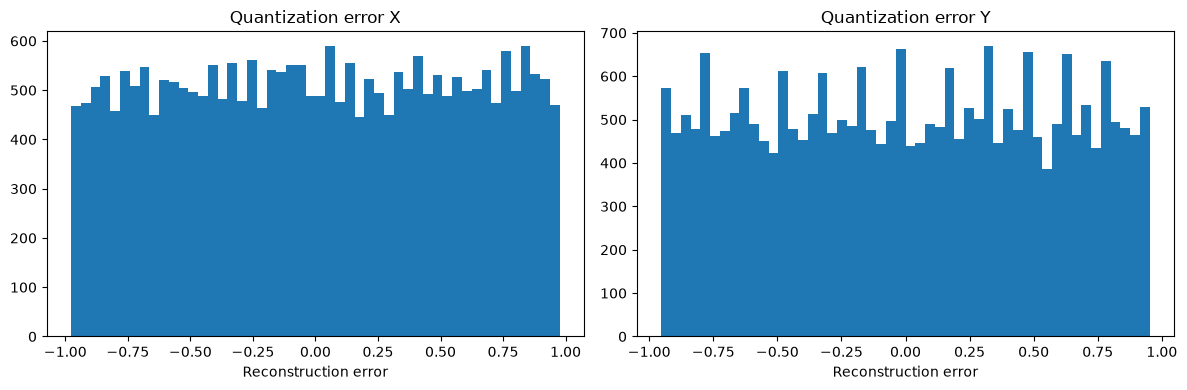

In [6]:
all_tokens = action_tokenizer.encode(actions)
reconstructed_actions = action_tokenizer.decode(all_tokens)

errors = reconstructed_actions - actions

mae = np.mean(np.abs(errors), axis=0)
max_error = np.max(np.abs(errors), axis=0)

print("MAE X/Y:", mae)
print("Max error X/Y:", max_error)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(errors[:, 0], bins=50)
axes[0].set_title("Quantization error X")
axes[0].set_xlabel("Reconstruction error")

axes[1].hist(errors[:, 1], bins=50)
axes[1].set_title("Quantization error Y")
axes[1].set_xlabel("Reconstruction error")

plt.tight_layout()
plt.show()

In [7]:
step_size = (action_max - action_min) / 255
theoretical_max_error = step_size / 2

print("Quantization step X/Y:", step_size)
print("Theoretical max error X/Y:", theoretical_max_error)
print("Observed max error X/Y:", max_error)

Quantization step X/Y: [1.9568627 1.9058824]
Theoretical max error X/Y: [0.97843134 0.9529412 ]
Observed max error X/Y: [0.97647059 0.95294118]


## 3. Autoregressive Action Generation

After quantization, continuous robot actions can be
represented as discrete action tokens.

An autoregressive VLA predicts these tokens sequentially.

For a two-dimensional action:

$$
a = [x,y]
$$

the action tokenizer produces:

$$
q = [q_x,q_y]
$$

An autoregressive model factorizes the action distribution as:

$$
p(q_x,q_y \mid I,L)
=
p(q_x \mid I,L)
p(q_y \mid q_x,I,L)
$$

This is analogous to next-token prediction in a language model.

The key difference is that generated tokens represent
robot actions rather than natural language.

After generation, the action tokenizer maps the discrete
tokens back to continuous robot commands.

In [8]:
example_actions = actions[:4]
example_tokens = action_tokenizer.encode(example_actions)

# Reserve token ID 256 as a special beginning-of-action token.
BOS_ACTION = 256

# Input sequence: [BOS, q_x]
decoder_inputs = np.column_stack([
    np.full(len(example_tokens), BOS_ACTION),
    example_tokens[:, 0],
])

# Target sequence: [q_x, q_y]
decoder_targets = example_tokens

print("Continuous actions:")
print(example_actions)

print("\nDecoder inputs:")
print(decoder_inputs)

print("\nDecoder targets:")
print(decoder_targets)

Continuous actions:
[[233.  71.]
 [229.  83.]
 [229.  86.]
 [230.  86.]]

Decoder inputs:
[[256 113]
 [256 111]
 [256 111]
 [256 111]]

Decoder targets:
[[113  24]
 [111  30]
 [111  32]
 [111  32]]


In [ ]:
# Simulate a perfect prediction using ground-truth tokens
predicted_action_tokens = decoder_targets[0]

# Convert discrete tokens back to continuous actions
continuous_action = action_tokenizer.decode(
    predicted_action_tokens
)

print("Original action:", example_actions[0])
print("Predicted tokens:", predicted_action_tokens)
print("Decoded action:", continuous_action)

Original action: [233.  71.]
Predicted tokens: [113  24]
Decoded action: [233.1254902   70.74117647]


### 3.2 Action Token Prediction and Cross-Entropy Loss

An autoregressive action decoder predicts a probability
distribution over discrete action tokens.

For PushT, each action contains two coordinates, and
each coordinate is quantized into 256 bins.

The decoder outputs:

$$
Z \in \mathbb{R}^{B \times 2 \times 256}
$$

where $Z$ contains unnormalized logits.

The probability of action token $k$ at position $i$ is:

$$
p(q_i=k) =
\frac{\exp(Z_{i,k})}
{\sum_{j=0}^{255}\exp(Z_{i,j})}
$$

Training uses cross-entropy loss against the ground-truth
action tokens:

$$
\mathcal{L}_{action}
=
-\frac{1}{2}
\left[
\log p(q_x \mid I,L)
+
\log p(q_y \mid q_x,I,L)
\right]
$$

During training, the decoder receives ground-truth
previous tokens (teacher forcing).

During inference, it must use its own predictions.

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

class ActionDecoder(nn.Module):
    def __init__(self, num_bins=256, d_model=128):
        super().__init__()

        # 256 action tokens + 1 BOS token
        self.token_embedding = nn.Embedding(
            num_bins + 1, d_model
        )

        self.position_embedding = nn.Embedding(
            2, d_model
        )

        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=4,
            dim_feedforward=256,
            batch_first=True,
        )

        self.transformer = nn.TransformerEncoder(
            layer,
            num_layers=2,
        )

        self.action_head = nn.Linear(
            d_model, num_bins
        )

    def forward(self, token_ids):
        B, T = token_ids.shape

        positions = torch.arange(
            T, device=token_ids.device
        )

        x = (
            self.token_embedding(token_ids)
            + self.position_embedding(positions)
        )

        # True = masked (future tokens cannot be read)
        causal_mask = torch.triu(
            torch.ones(
                T, T,
                dtype=torch.bool,
                device=token_ids.device,
            ),
            diagonal=1,
        )

        x = self.transformer(
            x,
            mask=causal_mask,
        )

        return self.action_head(x)


decoder = ActionDecoder().to(device)

input_tensor = torch.tensor(
    decoder_inputs,
    dtype=torch.long,
    device=device,
)

target_tensor = torch.tensor(
    decoder_targets,
    dtype=torch.long,
    device=device,
)

logits = decoder(input_tensor)

print("Decoder input:", input_tensor.shape)
print("Logits:", logits.shape)
print("Targets:", target_tensor.shape)

Decoder input: torch.Size([4, 2])
Logits: torch.Size([4, 2, 256])
Targets: torch.Size([4, 2])


In [11]:
loss = F.cross_entropy(
    logits.reshape(-1, 256),
    target_tensor.reshape(-1),
)

print("Action prediction loss:", loss.item())
print("Uniform baseline:", np.log(256))

Action prediction loss: 4.943007469177246
Uniform baseline: 5.545177444479562


In [12]:
decoder.eval()

generated = torch.tensor(
    [[BOS_ACTION]],
    dtype=torch.long,
    device=device,
)
print("Initial generated sequence:", generated.shape)

with torch.inference_mode():
    for step in range(2):
        logits = decoder(generated)

        # Next-token prediction
        next_token = logits[:, -1, :].argmax(
            dim=-1,
            keepdim=True,
        )

        generated = torch.cat(
            [generated, next_token],
            dim=1,
        )

predicted_action_tokens = (
    generated[0, 1:].cpu().numpy()
)

predicted_action = action_tokenizer.decode(
    predicted_action_tokens
)

print("Generated sequence:", generated)
print("Predicted action tokens:", predicted_action_tokens)
print("Decoded continuous action:", predicted_action)

Initial generated sequence: torch.Size([1, 1])
Generated sequence: tensor([[256, 177, 113]], device='mps:0')
Predicted action tokens: [177 113]
Decoded continuous action: [358.36470588 240.36470588]


## 4. Continuous Action Generation with Flow Matching

Autoregressive VLAs can represent robot actions as
discrete tokens and generate them sequentially.

An alternative is to generate continuous action chunks
using flow matching.

The π₀ architecture combines a pretrained
vision-language backbone with a flow-matching action
expert.

The action expert predicts a velocity field that
transforms a noisy action sequence into a structured
robot action chunk.

Let:

$$
A_0 \sim \mathcal{N}(0,I)
$$

represent an initial noisy action chunk, and:

$$
A_1 \sim p_{\mathrm{data}}(A \mid o,l)
$$

represent a demonstrated action chunk conditioned on
the observation and language instruction.

During training, we sample an interpolation:

$$
A_\tau = (1-\tau)A_0+\tau A_1
$$

where:

$$
\tau \sim \mathcal{U}(0,1)
$$

The target velocity is:

$$
u_\tau=A_1-A_0
$$

A neural network predicts:

$$
v_\theta(A_\tau,\tau,o,l)
$$

and is trained using:

$$
\mathcal{L}_{FM}
=
\mathbb{E}
\left[
\left\|
v_\theta(A_\tau,\tau,o,l)-u_\tau
\right\|^2
\right]
$$

At inference time, the learned velocity field is
integrated to transform noise into a continuous
action chunk.

This is the same fundamental flow-matching mechanism
studied earlier, now conditioned on multimodal
robot observations.

In [13]:
import torch
import matplotlib.pyplot as plt

H = 16

# One demonstrated action chunk
A1 = torch.tensor(
    actions[100:100 + H],
    dtype=torch.float32,
    device=device,
)

# Normalize using our existing action tokenizer
A1_normalized = torch.tensor(
    action_tokenizer.normalize(A1.cpu().numpy()),
    dtype=torch.float32,
    device=device,
)

# Initial Gaussian noise
A0 = torch.randn_like(A1_normalized)

# Flow-matching interpolation
tau = 0.4

A_tau = (1 - tau) * A0 + tau * A1_normalized

# Target velocity
target_velocity = A1_normalized - A0

print("Demonstration chunk:", A1_normalized.shape)
print("Noise chunk:", A0.shape)
print("Interpolated chunk:", A_tau.shape)
print("Target velocity:", target_velocity.shape)

Demonstration chunk: torch.Size([16, 2])
Noise chunk: torch.Size([16, 2])
Interpolated chunk: torch.Size([16, 2])
Target velocity: torch.Size([16, 2])


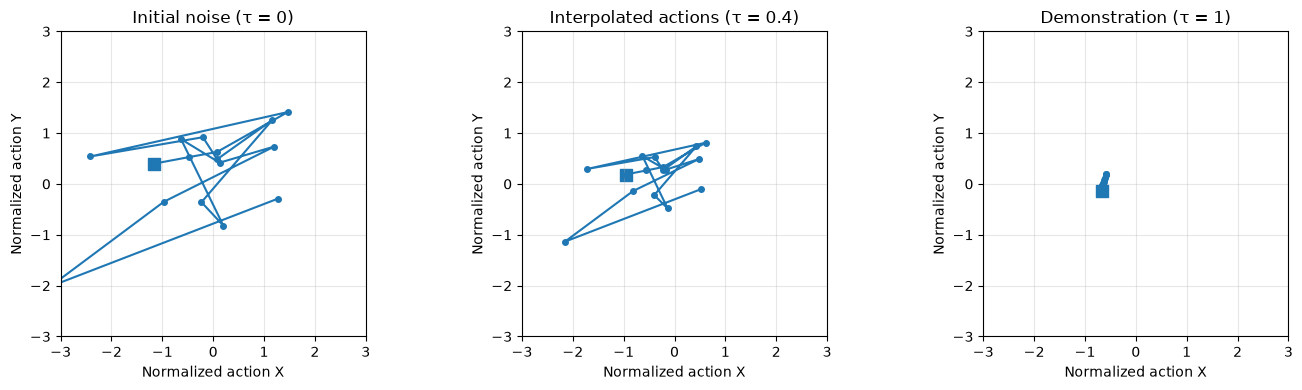

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

chunks = [
    A0,
    A_tau,
    A1_normalized,
]

titles = [
    "Initial noise (τ = 0)",
    "Interpolated actions (τ = 0.4)",
    "Demonstration (τ = 1)",
]

for ax, chunk, title in zip(axes, chunks, titles):
    xy = chunk.detach().cpu().numpy()

    ax.plot(xy[:, 0], xy[:, 1], "o-", markersize=4)
    ax.scatter(xy[0, 0], xy[0, 1], s=80, marker="s",
               label="Start")
    ax.set_title(title)
    ax.set_xlabel("Normalized action X")
    ax.set_ylabel("Normalized action Y")
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 4.2 Conditioning the Flow-Matching Action Expert

In unconditional flow matching, the velocity network
predicts how to transform noisy samples into data samples.

For robot control, the predicted velocity must depend on
the current observation and the task instruction.

The conditional velocity field is:

$$
v_\theta(A_\tau, \tau \mid I, L, s)
$$

where:

- $I$ is the visual observation.
- $L$ is the language instruction.
- $s$ is the robot state.
- $A_\tau$ is the noisy action chunk.
- $\tau$ is the flow-matching interpolation time.

In π₀, a vision-language backbone provides multimodal
context to an action expert.

The action expert processes robot state, noisy action
tokens, and flow time, while interacting with the
vision-language representations through attention.

The output is a continuous velocity prediction for
the entire action chunk.

We will first inspect the required tensor shapes,
without training another flow-matching model.

In [15]:
import torch

B = 1
H = 16
action_dim = 2
state_dim = 2
hidden_dim = 256
context_tokens = 32

# Simulated VLM context
vlm_context = torch.randn(
    B, context_tokens, hidden_dim,
    device=device,
)

# Real PushT robot state
robot_state = dataset[100]["observation.state"]

robot_state = robot_state.unsqueeze(0).to(
    device=device,
    dtype=torch.float32,
)

# Demonstrated action chunk, already normalized
clean_actions = A1_normalized.unsqueeze(0)

# Gaussian noise
noise = torch.randn_like(clean_actions)

# One flow time per batch element
tau = torch.rand(B, device=device)

# Broadcast tau across horizon and action dimensions
tau_expanded = tau[:, None, None]

noisy_actions = (
    (1 - tau_expanded) * noise
    + tau_expanded * clean_actions
)

target_velocity = clean_actions - noise

print("VLM context:", vlm_context.shape)
print("Robot state:", robot_state.shape)
print("Noisy actions:", noisy_actions.shape)
print("Flow time:", tau.shape)
print("Target velocity:", target_velocity.shape)

VLM context: torch.Size([1, 32, 256])
Robot state: torch.Size([1, 2])
Noisy actions: torch.Size([1, 16, 2])
Flow time: torch.Size([1])
Target velocity: torch.Size([1, 16, 2])


### 4.5 Cross-Attention Between Action Tokens and VLM Context

A flow-matching action expert predicts a velocity field
for a noisy action chunk.

To condition this prediction on visual and linguistic
information, action tokens must interact with the
representations produced by the VLM.

One possible mechanism is cross-attention.

The action tokens provide the queries:

$$
Q = E_A W_Q
$$

The VLM context provides keys and values:

$$
K = C_{\mathrm{VLM}} W_K
$$

$$
V = C_{\mathrm{VLM}} W_V
$$

Cross-attention computes:

$$
\operatorname{Attention}(Q,K,V)
=
\operatorname{softmax}
\left(
\frac{QK^\top}{\sqrt{d_k}}
\right)V
$$

This allows each action token to retrieve information
from the visual-language context.

We implement a simplified action expert with
cross-attention to understand the tensor operations.

This is a pedagogical architecture, not an exact
implementation of the π₀ action expert.

In [16]:
import torch
import torch.nn as nn

class SimpleActionExpert(nn.Module):
    def __init__(
        self,
        action_dim=2,
        state_dim=2,
        hidden_dim=256,
        num_heads=4,
    ):
        super().__init__()

        # Convert continuous actions into action tokens
        self.action_embedding = nn.Linear(
            action_dim, hidden_dim
        )

        # Encode robot state and flow time
        self.state_embedding = nn.Linear(
            state_dim, hidden_dim
        )

        self.time_embedding = nn.Linear(
            1, hidden_dim
        )

        # Action tokens query the VLM context
        self.cross_attention = nn.MultiheadAttention(
            embed_dim=hidden_dim,
            num_heads=num_heads,
            batch_first=True,
        )

        self.norm = nn.LayerNorm(hidden_dim)

        self.velocity_head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, action_dim),
        )

    def forward(
        self,
        noisy_actions,
        tau,
        robot_state,
        vlm_context,
    ):
        # [B, H, 2] -> [B, H, 256]
        action_tokens = self.action_embedding(
            noisy_actions
        )

        # [B, 2] -> [B, 1, 256]
        state_token = self.state_embedding(
            robot_state
        ).unsqueeze(1)

        # [B] -> [B, 1, 256]
        time_token = self.time_embedding(
            tau[:, None]
        ).unsqueeze(1)

        # Broadcast state and time information
        action_tokens = (
            action_tokens
            + state_token
            + time_token
        )

        # Q = action tokens
        # K, V = VLM context
        attended, attention_weights = self.cross_attention(
            query=action_tokens,
            key=vlm_context,
            value=vlm_context,
            need_weights=True,
        )

        # Residual connection
        action_features = self.norm(
            action_tokens + attended
        )

        # Predict continuous velocity
        predicted_velocity = self.velocity_head(
            action_features
        )

        return predicted_velocity, attention_weights


action_expert = SimpleActionExpert().to(device)

predicted_velocity, attention_weights = action_expert(
    noisy_actions=noisy_actions,
    tau=tau,
    robot_state=robot_state,
    vlm_context=vlm_context,
)

print("Predicted velocity:", predicted_velocity.shape)
print("Attention weights:", attention_weights.shape)
print("Target velocity:", target_velocity.shape)

Predicted velocity: torch.Size([1, 16, 2])
Attention weights: torch.Size([1, 16, 32])
Target velocity: torch.Size([1, 16, 2])


In [17]:
import torch.nn.functional as F

loss = F.mse_loss(
    predicted_velocity,
    target_velocity,
)

print("Flow matching loss:", loss.item())

Flow matching loss: 1.335858941078186


In [18]:
action_expert.zero_grad()

loss.backward()

print(
    "Action embedding gradient:",
    action_expert.action_embedding.weight.grad.norm().item()
)

print(
    "Cross-attention gradient:",
    action_expert.cross_attention.in_proj_weight.grad.norm().item()
)

print(
    "Velocity head gradient:",
    action_expert.velocity_head[0].weight.grad.norm().item()
)

Action embedding gradient: 0.0029582888819277287
Cross-attention gradient: 0.019689079374074936
Velocity head gradient: 5.475316047668457


### 4.8 Temporal Positional Embeddings

An action chunk is an ordered sequence of robot commands.

For an action horizon $H$, the action expert processes:

$$
A_t = [a_t, a_{t+1}, \ldots, a_{t+H-1}]
$$

Attention mechanisms do not inherently encode the
temporal order of tokens.

We can introduce learned positional embeddings:

$$
E_A = \operatorname{Linear}(A_\tau) + P
$$

where:

$$
P \in \mathbb{R}^{H \times d}
$$

Each action token receives a different positional
representation.

This allows the action expert to distinguish actions
at different positions within the predicted chunk.

We use learned positional embeddings in our simplified
implementation. Real VLA architectures may employ
different positional encoding mechanisms.

In [19]:
class TemporalActionExpert(SimpleActionExpert):
    def __init__(
        self,
        action_dim=2,
        state_dim=2,
        hidden_dim=256,
        num_heads=4,
        horizon=16,
    ):
        super().__init__(
            action_dim=action_dim,
            state_dim=state_dim,
            hidden_dim=hidden_dim,
            num_heads=num_heads,
        )

        self.position_embedding = nn.Embedding(
            horizon, hidden_dim
        )

    def forward(
        self,
        noisy_actions,
        tau,
        robot_state,
        vlm_context,
    ):
        B, H, _ = noisy_actions.shape

        positions = torch.arange(
            H, device=noisy_actions.device
        )

        action_tokens = (
            self.action_embedding(noisy_actions)
            + self.position_embedding(positions)[None, :, :]
        )

        state_token = self.state_embedding(
            robot_state
        ).unsqueeze(1)

        time_token = self.time_embedding(
            tau[:, None]
        ).unsqueeze(1)

        action_tokens = (
            action_tokens + state_token + time_token
        )

        attended, attention_weights = self.cross_attention(
            query=action_tokens,
            key=vlm_context,
            value=vlm_context,
            need_weights=True,
        )

        action_features = self.norm(
            action_tokens + attended
        )

        predicted_velocity = self.velocity_head(
            action_features
        )

        return predicted_velocity, attention_weights

In [20]:
class TemporalActionExpert(SimpleActionExpert):
    def __init__(
        self,
        action_dim=2,
        state_dim=2,
        hidden_dim=256,
        num_heads=4,
        horizon=16,
    ):
        super().__init__(
            action_dim=action_dim,
            state_dim=state_dim,
            hidden_dim=hidden_dim,
            num_heads=num_heads,
        )

        self.position_embedding = nn.Embedding(
            horizon, hidden_dim
        )

    def forward(
        self,
        noisy_actions,
        tau,
        robot_state,
        vlm_context,
    ):
        B, H, _ = noisy_actions.shape

        positions = torch.arange(
            H, device=noisy_actions.device
        )

        action_tokens = (
            self.action_embedding(noisy_actions)
            + self.position_embedding(positions)[None, :, :]
        )

        state_token = self.state_embedding(
            robot_state
        ).unsqueeze(1)

        time_token = self.time_embedding(
            tau[:, None]
        ).unsqueeze(1)

        action_tokens = (
            action_tokens + state_token + time_token
        )

        attended, attention_weights = self.cross_attention(
            query=action_tokens,
            key=vlm_context,
            value=vlm_context,
            need_weights=True,
        )

        action_features = self.norm(
            action_tokens + attended
        )

        predicted_velocity = self.velocity_head(
            action_features
        )

        return predicted_velocity, attention_weights

In [21]:
temporal_expert = TemporalActionExpert(
    horizon=H
).to(device)

velocity, attention = temporal_expert(
    noisy_actions=noisy_actions,
    tau=tau,
    robot_state=robot_state,
    vlm_context=vlm_context,
)

print("Temporal embeddings:",
      temporal_expert.position_embedding.weight.shape)

print("Predicted velocity:", velocity.shape)
print("Attention weights:", attention.shape)

Temporal embeddings: torch.Size([16, 256])
Predicted velocity: torch.Size([1, 16, 2])
Attention weights: torch.Size([1, 16, 32])


## 5. Understanding the Real π₀ Architecture

Our simplified action expert used cross-attention:

- Action tokens provided the queries.
- VLM context tokens provided the keys and values.
- A velocity head predicted continuous action velocities.

The real π₀ architecture uses a more integrated approach.

It combines:

1. A pretrained vision-language backbone.
2. A dedicated action expert.
3. Joint attention across vision-language and action tokens.
4. Flow matching for continuous action chunk generation.

The action expert processes noisy actions, robot state,
and flow time while accessing multimodal context.

Unlike a standard autoregressive language model,
the action expert predicts continuous velocity vectors
for an entire action chunk.

The goal is to learn:

$$
v_\theta(A_\tau, \tau \mid I, L, s)
$$

The following experiment illustrates how joint attention
differs from an independent cross-attention layer.

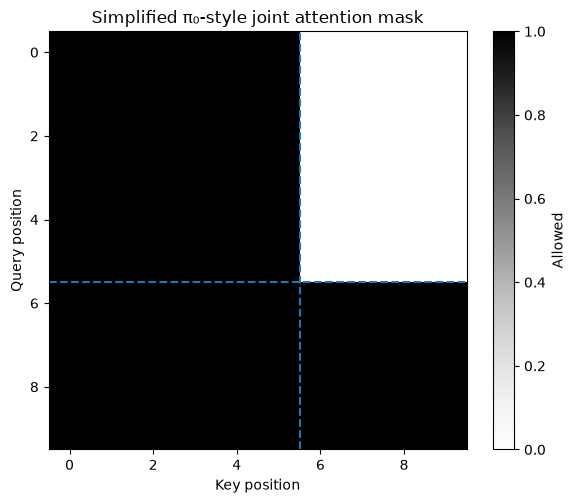

In [ ]:
import torch
import matplotlib.pyplot as plt

# suppose we have 6 token VLM and 4 action token. We want to allows:
# - VLM → VLM
# - Action → VLM
# - Action → Action
# - Not VLM → Action

n_vlm = 6
n_action = 4
n_total = n_vlm + n_action

# True means attention is allowed
allowed = torch.ones(
    n_total, n_total, dtype=torch.bool
)

# VLM queries cannot read action keys: disable VLM → Action 
allowed[:n_vlm, n_vlm:] = False

plt.figure(figsize=(6, 5))
plt.imshow(
    allowed.numpy(),
    cmap="Greys",
    vmin=0,
    vmax=1,
)

plt.axvline(n_vlm - 0.5, color="tab:blue", linestyle="--")
plt.axhline(n_vlm - 0.5, color="tab:blue", linestyle="--")

plt.xlabel("Key position")
plt.ylabel("Query position")
plt.title("Simplified π₀-style joint attention mask")
plt.colorbar(label="Allowed")
plt.tight_layout()
plt.show()

In [23]:
import torch.nn as nn
import torch.nn.functional as F

class JointAttentionDemo(nn.Module):
    def __init__(self, dim=256, heads=4):
        super().__init__()

        self.heads = heads
        self.head_dim = dim // heads

        self.vlm_qkv = nn.Linear(dim, 3 * dim)
        self.action_qkv = nn.Linear(dim, 3 * dim)

        self.vlm_out = nn.Linear(dim, dim)
        self.action_out = nn.Linear(dim, dim)

    def split_qkv(self, x, projection):
        B, N, D = x.shape

        qkv = projection(x).reshape(
            B, N, 3, self.heads, self.head_dim
        )

        q, k, v = qkv.unbind(dim=2)

        return (
            q.transpose(1, 2),
            k.transpose(1, 2),
            v.transpose(1, 2),
        )

    def forward(self, vlm_tokens, action_tokens):
        B, Nv, D = vlm_tokens.shape
        Na = action_tokens.shape[1]

        qv, kv, vv = self.split_qkv(
            vlm_tokens, self.vlm_qkv
        )

        qa, ka, va = self.split_qkv(
            action_tokens, self.action_qkv
        )

        q = torch.cat([qv, qa], dim=2)
        k = torch.cat([kv, ka], dim=2)
        v = torch.cat([vv, va], dim=2)

        # Mask: VLM cannot attend to action tokens
        mask = torch.ones(
            Nv + Na, Nv + Na,
            dtype=torch.bool,
            device=q.device,
        )
        mask[:Nv, Nv:] = False

        output = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=mask,
            dropout_p=0.0,
        )

        output = output.transpose(1, 2).reshape(
            B, Nv + Na, D
        )

        vlm_output = self.vlm_out(output[:, :Nv])
        action_output = self.action_out(output[:, Nv:])

        return vlm_output, action_output


joint_attention = JointAttentionDemo().to(device)

# Reuse simulated VLM context
vlm_tokens = vlm_context

# Reuse the action embedding from our previous expert
with torch.no_grad():
    action_tokens = temporal_expert.action_embedding(
        noisy_actions
    )

vlm_output, action_output = joint_attention(
    vlm_tokens,
    action_tokens,
)

print("VLM output:", vlm_output.shape)
print("Action output:", action_output.shape)

VLM output: torch.Size([1, 32, 256])
Action output: torch.Size([1, 16, 256])


In [24]:
x = vlm_context

B, N, D = x.shape

print("Input:", x.shape)

projected = joint_attention.vlm_qkv(x)
print("After linear:", projected.shape)

reshaped = projected.reshape(
    B, N, 3,
    joint_attention.heads,
    joint_attention.head_dim,
)
print("After reshape:", reshaped.shape)

q, k, v = reshaped.unbind(dim=2)
print("After unbind:", q.shape, k.shape, v.shape)

q = q.transpose(1, 2)
k = k.transpose(1, 2)
v = v.transpose(1, 2)

print("After transpose:", q.shape, k.shape, v.shape)

Input: torch.Size([1, 32, 256])
After linear: torch.Size([1, 32, 768])
After reshape: torch.Size([1, 32, 3, 4, 64])
After unbind: torch.Size([1, 32, 4, 64]) torch.Size([1, 32, 4, 64]) torch.Size([1, 32, 4, 64])
After transpose: torch.Size([1, 4, 32, 64]) torch.Size([1, 4, 32, 64]) torch.Size([1, 4, 32, 64])


## 5.4 π₀: Prefix and Suffix Tokens

The π₀ architecture organizes its multimodal inputs into
two groups.

**Prefix tokens** represent visual and linguistic context.

They are processed by the vision-language backbone and
provide information about the environment and task.

**Suffix tokens** represent the robot-control inputs:

- Robot state.
- Noisy action chunk.
- Flow-matching time.

They are processed by the action expert.

The two token groups interact through joint attention,
subject to an attention mask.

During inference, the visual-language context can be
cached while the noisy action chunk evolves through
flow-matching integration steps.

We will inspect how these inputs are embedded before
entering the Transformer layers.

In [ ]:
# from LeRobot pi0

# embed_prefix(images, img_masks, lang_tokens, lang_masks)
#   run PaliGemma visual encoder for each image in the batch
#   linguistic tokens are embedded and concatenated to the visual embeddings
#   return embs, pad_masks, att_masks

# embed_suffix(state, noisy_actions, timestep)
#   embed robot state and flow time
#   embed noisy actions and add positional embeddings
#   MLP to produce action tokens

In [25]:
from lerobot.policies.common.vla_utils import (
    create_sinusoidal_pos_embedding,
)

hidden_dim = 256

action_proj = nn.Linear(2, hidden_dim).to(device)
time_mlp = nn.Sequential(
    nn.Linear(2 * hidden_dim, hidden_dim),
    nn.SiLU(),
    nn.Linear(hidden_dim, hidden_dim),
).to(device)

action_emb = action_proj(noisy_actions)

time_emb = create_sinusoidal_pos_embedding(
    tau,
    hidden_dim,
    min_period=4e-3,
    max_period=4.0,
    device=device,
)

time_emb = time_emb.to(action_emb.dtype)
time_emb = time_emb[:, None, :].expand_as(action_emb)

action_time_emb = torch.cat(
    [action_emb, time_emb],
    dim=-1,
)

fused_action_tokens = time_mlp(action_time_emb)

print("Action embedding:", action_emb.shape)
print("Time embedding:", time_emb.shape)
print("Concatenated:", action_time_emb.shape)
print("Fused tokens:", fused_action_tokens.shape)

Action embedding: torch.Size([1, 16, 256])
Time embedding: torch.Size([1, 16, 256])
Concatenated: torch.Size([1, 16, 512])
Fused tokens: torch.Size([1, 16, 256])


### 5.7 Flow-Matching Inference and KV Caching

During inference, π₀ generates a continuous action chunk
by integrating a learned velocity field.

The visual-language prefix remains constant throughout
the integration process.

Its Key and Value representations can therefore be
computed once and stored in a KV cache.

At each integration step:

1. Embed the current noisy action chunk.
2. Embed the current flow time and robot state.
3. Process the action suffix using the cached prefix.
4. Predict the action velocity field.
5. Update the action chunk.

In the LeRobot π₀ implementation, the flow follows
the convention:

$$
A_\tau = \tau \epsilon + (1-\tau) A
$$

where noise corresponds to $\tau=1$ and clean actions
correspond to $\tau=0$.

The inference process starts from Gaussian noise and
integrates backward in flow time:

$$
A_{\tau+\Delta\tau}
=
A_\tau+\Delta\tau\,v_\theta(A_\tau,\tau,c)
$$

with $\Delta\tau<0$.

The velocity network is conditioned on the observation,
language instruction, robot state, and current noisy
action chunk.

In [26]:
import torch

@torch.no_grad()
def sample_action_chunk(
    model,
    vlm_context,
    robot_state,
    horizon=16,
    action_dim=2,
    num_steps=10,
):
    B = robot_state.shape[0]

    # Start from Gaussian noise at tau = 1
    actions = torch.randn(
        B, horizon, action_dim,
        device=robot_state.device,
    )

    dt = -1.0 / num_steps

    trajectory = [actions.clone()]

    model.eval()

    for step in range(num_steps):
        tau_value = 1.0 + step * dt

        tau = torch.full(
            (B,),
            tau_value,
            device=robot_state.device,
        )

        velocity, _ = model(
            noisy_actions=actions,
            tau=tau,
            robot_state=robot_state,
            vlm_context=vlm_context,
        )

        # Euler integration
        actions = actions + dt * velocity

        trajectory.append(actions.clone())

    return actions, torch.stack(trajectory)


sampled_actions, flow_trajectory = sample_action_chunk(
    model=temporal_expert,
    vlm_context=vlm_context,
    robot_state=robot_state,
    num_steps=10,
)

print("Generated action chunk:", sampled_actions.shape)
print("Flow trajectory:", flow_trajectory.shape)

Generated action chunk: torch.Size([1, 16, 2])
Flow trajectory: torch.Size([11, 1, 16, 2])


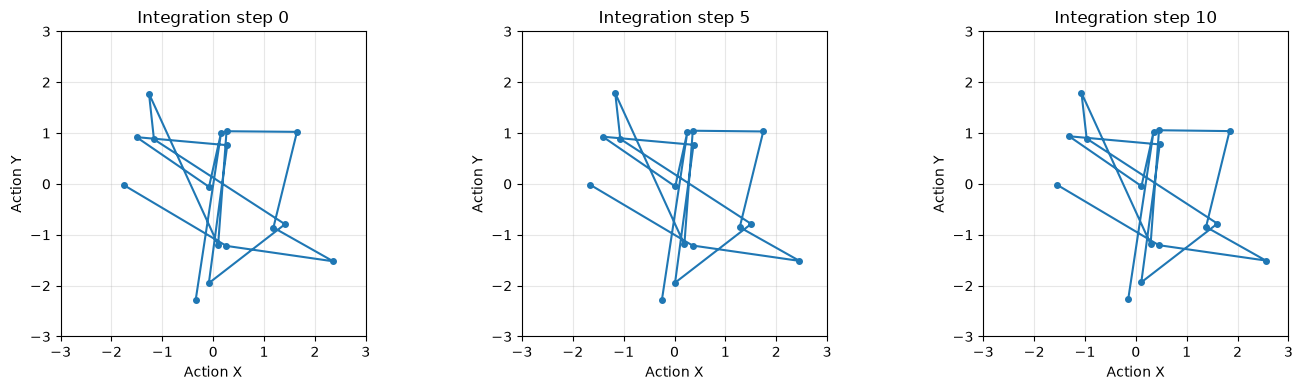

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

steps_to_plot = [0, 5, 10]

for ax, step in zip(axes, steps_to_plot):
    chunk = flow_trajectory[
        step, 0
    ].cpu().numpy()

    ax.plot(
        chunk[:, 0],
        chunk[:, 1],
        "o-",
        markersize=4,
    )

    ax.set_title(f"Integration step {step}")
    ax.set_xlabel("Action X")
    ax.set_ylabel("Action Y")
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
initial = flow_trajectory[0]
final = flow_trajectory[-1]

displacement = torch.linalg.vector_norm(
    final - initial,
    dim=-1,
)

print(
    "Mean displacement:",
    displacement.mean().item()
)

print(
    "Max displacement:",
    displacement.max().item()
)

print(
    "Initial action std:",
    initial.std().item()
)

print(
    "Final action std:",
    final.std().item()
)

Mean displacement: 0.19519422948360443
Max displacement: 0.19879749417304993
Initial action std: 1.196826457977295
Final action std: 1.2102243900299072


## 5.10 π₀ Inference: Sampling Actions with a KV Cache

During inference, π₀ generates an action chunk from
Gaussian noise using a learned velocity field.

The process has two distinct computational stages.

**Stage 1 — Encode the observation**

The visual-language backbone processes the image and
language instruction.

The resulting prefix Key and Value tensors are cached
because the observation remains unchanged during
the flow-matching integration.

**Stage 2 — Integrate the action flow**

Starting from Gaussian noise, the action expert
repeatedly:

1. Embeds the current noisy actions and flow time.
2. Attends to the cached visual-language prefix.
3. Predicts the velocity field.
4. Updates the action chunk using numerical integration.

For $N$ Euler steps:

$$
\Delta\tau=-\frac{1}{N}
$$

$$
A_{\tau+\Delta\tau}
=
A_\tau+\Delta\tau\,v_\theta(A_\tau,\tau,c)
$$

The integration starts at $\tau=1$ and ends at $\tau=0$.

Unlike autoregressive action-token generation, the
entire continuous action chunk is refined at each step.

In [29]:
import inspect

from lerobot.policies.pi0.modeling_pi0 import PI0Pytorch

print("PI0Pytorch source:")
print(inspect.getfile(PI0Pytorch))

for method_name in [
    "embed_prefix",
    "embed_suffix",
    "sample_actions",
    "denoise_step",
]:
    method = getattr(PI0Pytorch, method_name, None)

    print(f"\n{method_name}:")
    if method is None:
        print("Not available in this version")
    else:
        print(inspect.signature(method))

PI0Pytorch source:
/Users/terreran/Documents/ws-playground/robot-learning-playground/.pixi/envs/default/lib/python3.12/site-packages/lerobot/policies/pi0/modeling_pi0.py

embed_prefix:
(self, images, img_masks, lang_tokens, lang_masks) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]

embed_suffix:
(self, state, noisy_actions, timestep)

sample_actions:
(self, images, img_masks, lang_tokens, lang_masks, state, noise=None, num_steps=None, **kwargs: Unpack[lerobot.policies.pi0.modeling_pi0.ActionSelectKwargs]) -> torch.Tensor

denoise_step:
(self, state, prefix_pad_masks, past_key_values, x_t, timestep)


## Conclusion — From VLA Architectures to Robot Evaluation

In this notebook, we explored two major approaches
to vision-language-action modeling:

- Autoregressive generation of discretized actions,
  as illustrated by OpenVLA.
- Continuous action chunk generation through flow
  matching, as illustrated by π₀.

We implemented the essential mechanisms:

- Action tokenization and decoding.
- Autoregressive action prediction.
- Flow-matching interpolation and velocity prediction.
- Multimodal conditioning of an action expert.
- Cross-attention and joint attention.
- Temporal action representations.
- Iterative action generation and KV caching.

These experiments focused on understanding model
architecture rather than achieving task performance.

The next step is to evaluate pretrained robot policies
on simulation benchmarks.

We will focus on:

1. Loading pretrained policy checkpoints.
2. Running closed-loop robot rollouts.
3. Measuring task success and reward.
4. Visualizing successful and failed executions.
5. Understanding the gap between benchmark performance
   and real-world robotic deployment.

**Next notebook:** `13_pretrained_robot_policies.ipynb`